# Le temps de sommeil chez les étudiants
Notre travail de recherche s'intéresse à l'étude d'une base de donnée de 500 étudiants ayant répondus à une enquête portant sur la qualité de leur sommeil. Chaque ligne correspond donc à un étudiant intérogé et chaque colonnes représentent des variables qualitatives et quantitative telle que la qualité de sommeil, le chronotype de l'individu, le temps qu'il estime d'écran, le temps d'études/révision hebdomadaire, les appareils qu'il utilise : smartphone, tablette, ipad...). 

*Dans la description, il est toutefois expliqué que ces données ont été généré artificiellement à des fins de travaux d'entraînements à la régression. Notons d'ailleurs que l'auteur de cette base de donnée a émis volontairément des désordre réel tel que : des valeurs manquantes, de mauvaises notation en lettre capitale ou minuscule (F/H, homme/femme) afin desimuler les particularités réelles de donnée trouvées dans le contexte de réelles enquêtes*

# Première visualisation de notre base de donnée :
Dans cette première partie nous nous occuperons de :

- visualiser les premières lignes
- explorer les variable explicatives
- afficher les statistiques descriptives de bases *(moyenne, quartiles, etc...)*

In [6]:
import pandas as pd
df = pd.read_csv('time_sleep.csv')
df.head(5) # nous venons ici d'afficher les 5 premières lignes de notre dataframe.

,student_id,age,gender,year_of_study,major_category,residence_type,chronotype,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,...,naps_per_week,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,has_part_time_job,semester_type,cgpa
0,STU2001,21,Male,3,Humanities,With Family,Early Bird,22.3,7.6,2.0,...,0,10.0,7,5.0,7.0,15.6,80.0,No,Spring,2.99
1,STU2002,20,Female,2,STEM,Dormitory,Intermediate,23.1,5.9,2.7,...,3,7.0,3,6.0,7.0,17.5,78.9,No,Summer,2.88
2,STU2003,20,Male,4,Social Sciences,With Family,Intermediate,23.4,8.4,1.8,...,1,9.0,2,5.0,1.0,19.0,69.7,Yes,Spring,3.15
3,STU2004,22,F,1,Humanities,Off-campus Apartment,Night Owl,0.9,5.1,2.4,...,3,6.0,4,3.0,7.0,7.3,59.1,No,Fall,2.27
4,STU2005,23,Female,4,Social Sciences,Off-campus Apartment,Early Bird,23.4,5.9,2.0,...,2,7.0,6,8.0,3.0,23.6,79.9,No,Summer,2.74


In [5]:
df.shape # le dataframe contient 500 lignes et 25 variables explicatives.

(500, 25)

# Résumé statistique des données

In [ ]:
df.describe() 

,age,year_of_study,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,pre_sleep_screen_time_min,daily_screen_time_hours,caffeine_drinks_per_day,naps_per_week,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,cgpa
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,494.000000,500.000000,485.000000,486.000000,500.0000,500.000000,493.000000
mean,20.260000,2.954000,12.778200,6.608200,1.540600,38.388000,5.827000,1.502000,1.458000,7.271255,3.666000,5.758763,5.176955,16.5714,79.247200,2.833834
std,1.994079,1.405644,10.772656,1.435784,0.965441,23.573478,2.046193,1.273279,1.331082,2.131409,2.277019,1.981722,2.033119,6.9279,11.983513,0.334771
min,17.000000,1.000000,0.000000,1.500000,-1.000000,0.000000,0.500000,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.0000,34.600000,1.890000
25%,19.000000,2.000000,1.100000,5.700000,0.900000,22.000000,4.475000,1.000000,0.000000,6.000000,2.000000,4.000000,4.000000,12.1000,70.775000,2.620000
50%,20.000000,3.000000,21.500000,6.600000,1.500000,35.500000,5.800000,1.000000,1.000000,7.000000,4.000000,6.000000,5.000000,16.3000,79.800000,2.850000
75%,22.000000,4.000000,22.800000,7.700000,2.200000,54.000000,7.200000,2.000000,2.000000,9.000000,6.000000,7.000000,7.000000,20.3250,87.925000,3.050000
max,27.000000,5.000000,24.000000,10.500000,4.400000,240.000000,19.500000,7.000000,7.000000,10.000000,7.000000,10.000000,10.000000,88.5000,100.000000,3.950000


Par le biais de la commande **describe**, on affiche pour chaque variables explicatives :

- le nombre d'observation
- la moyenne 
- l'écart-type
- la valeur minimale et maximale
- les quartiles et la médiane *(25%,50%,75%)*


# Valeurs Manquantes

In [15]:
df.isna().sum().sum()

np.int64(51)

On dénombre ici 51 valeurs manquantes qu'il faudra donc nettoyer ou remplacer par des valeurs synthétiques *(imputation par la moyenne/médiane, KNN, autre)* dans la suite de notre travail de recheche.

# Lien entre les variables :
Cette partie s'inéressera aux relations potentielles entre nos variables et les potentielles relations *(positive/négative)* qui pourraient exister. Pour cela, nous aurons besoin de la méthode statistique de la **corrélation de Pearson**. Cela nous permet d'obtenir une valeur comprise entre **-1** et **1**. Ainsi, on dira que : 

- les valeurs proches de -1 décrivent une relation inverse entre les deux variables explicatives
- les valeurs proches de 0 ne décrivent aucune relation entre les deux variables explicatives
- les valeurs proches d 1 décrivent une relation positives entre les deux variables explicatives

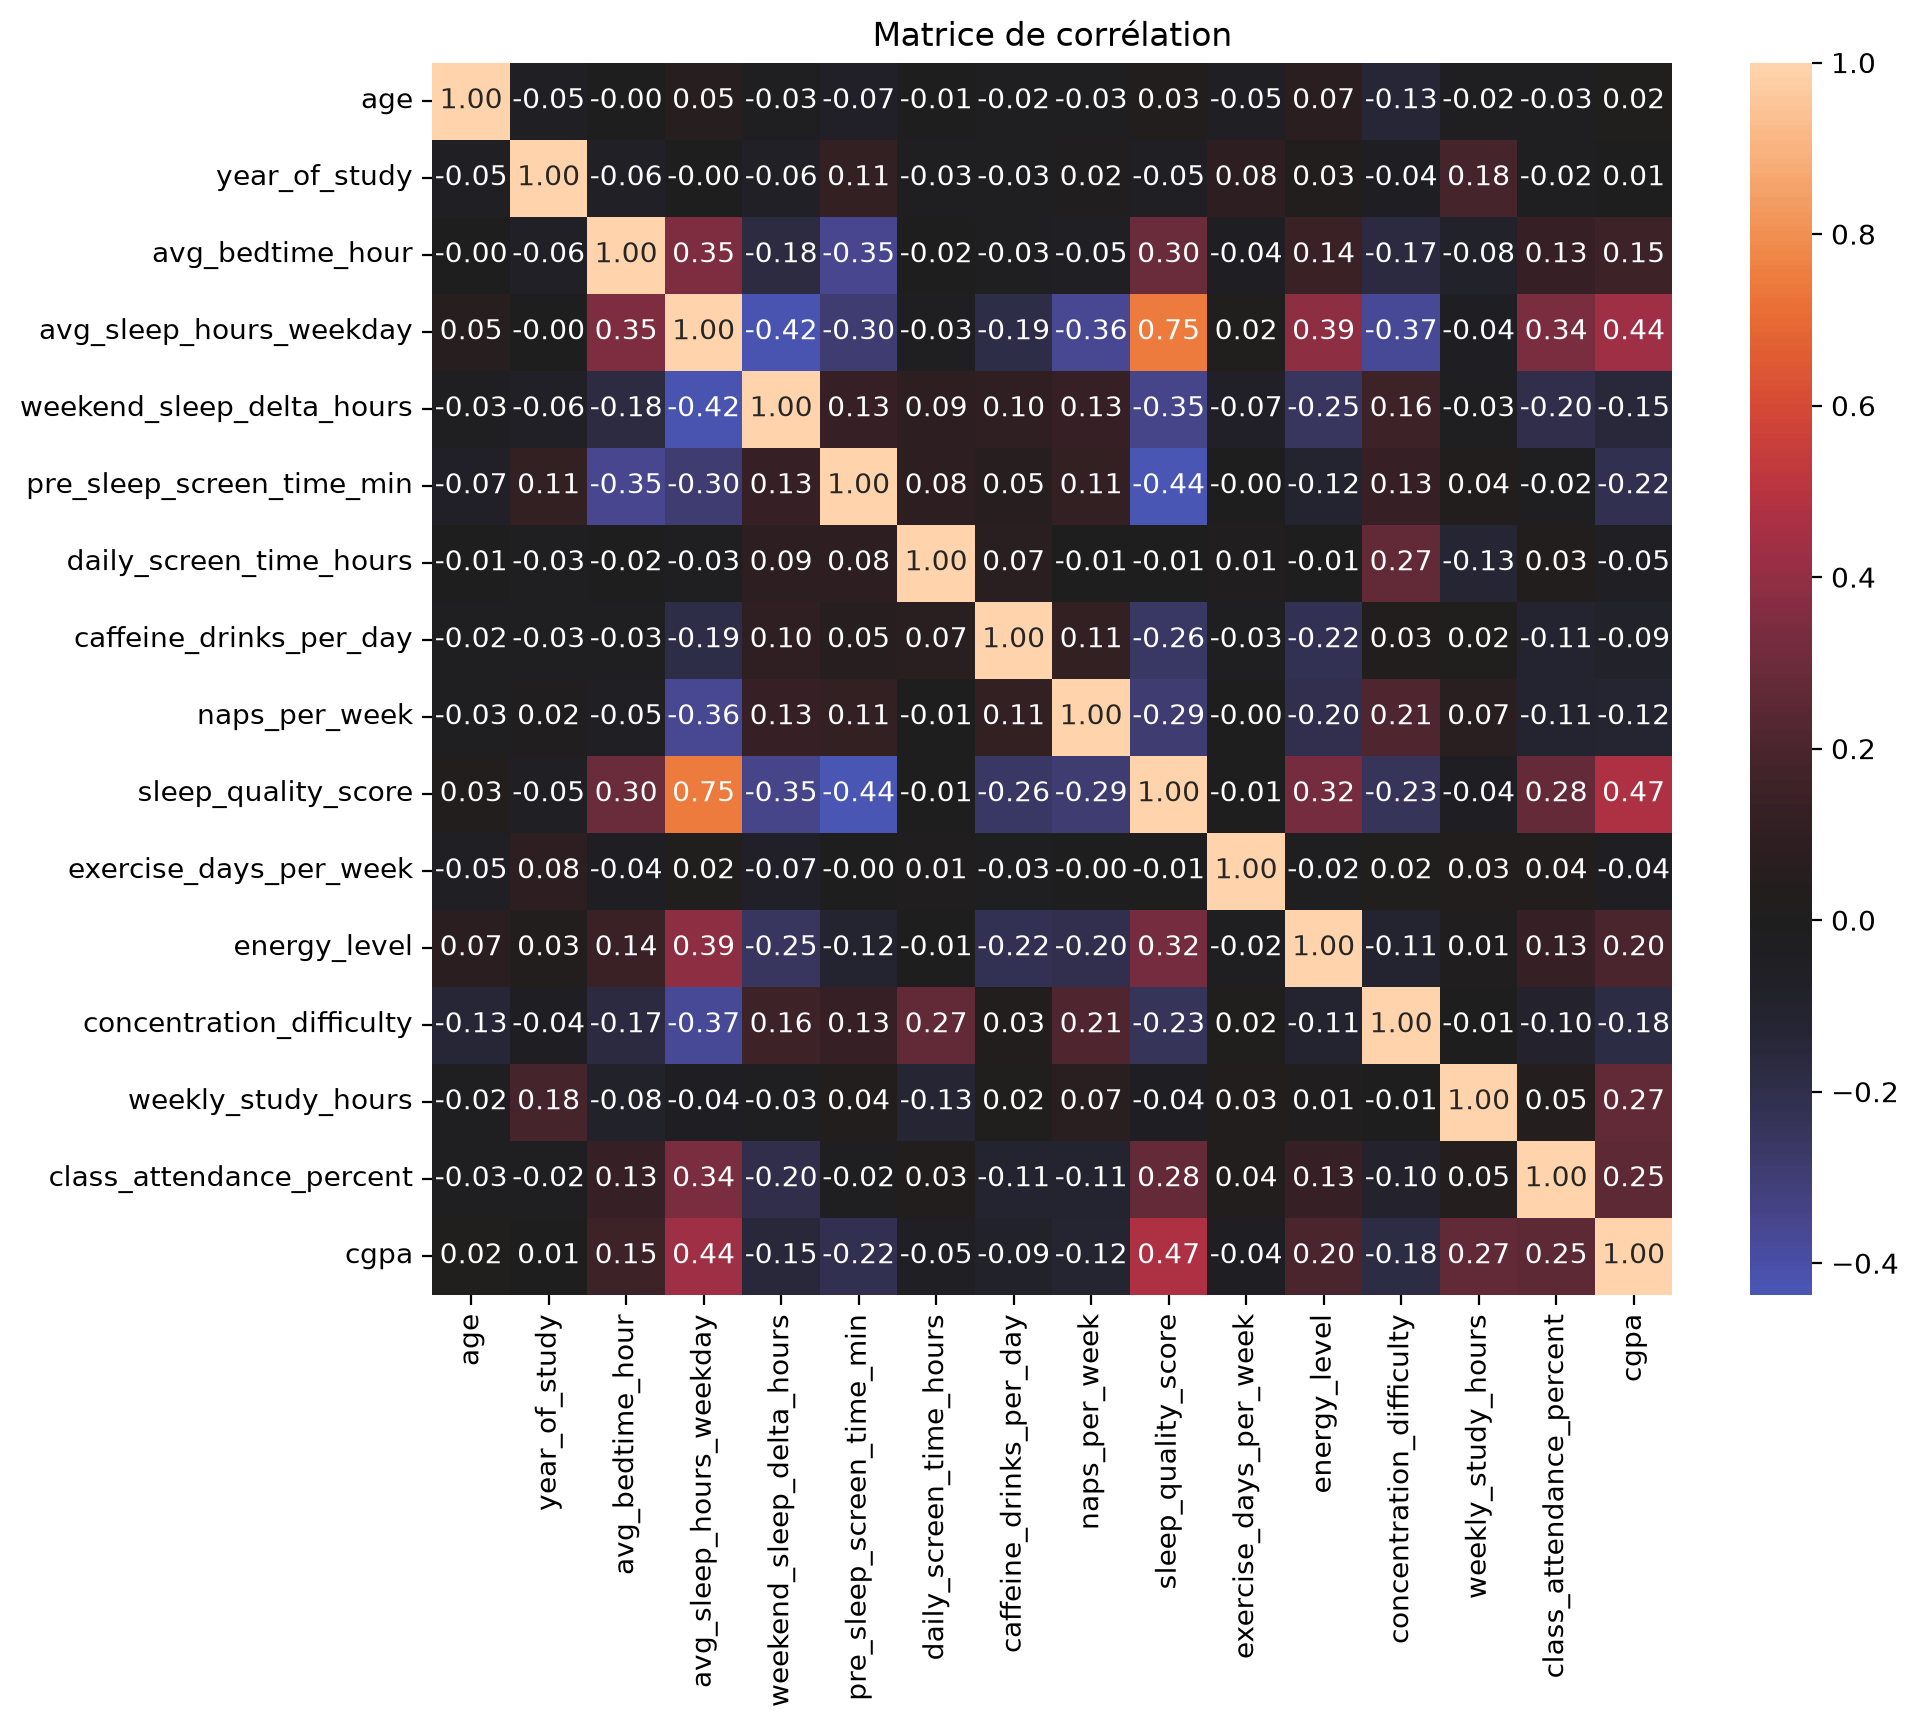

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

correlations = df.corr(numeric_only=True)
correlations
plt.figure(figsize=(10, 8))
sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    center=0
)

plt.title("Matrice de corrélation")
plt.show()

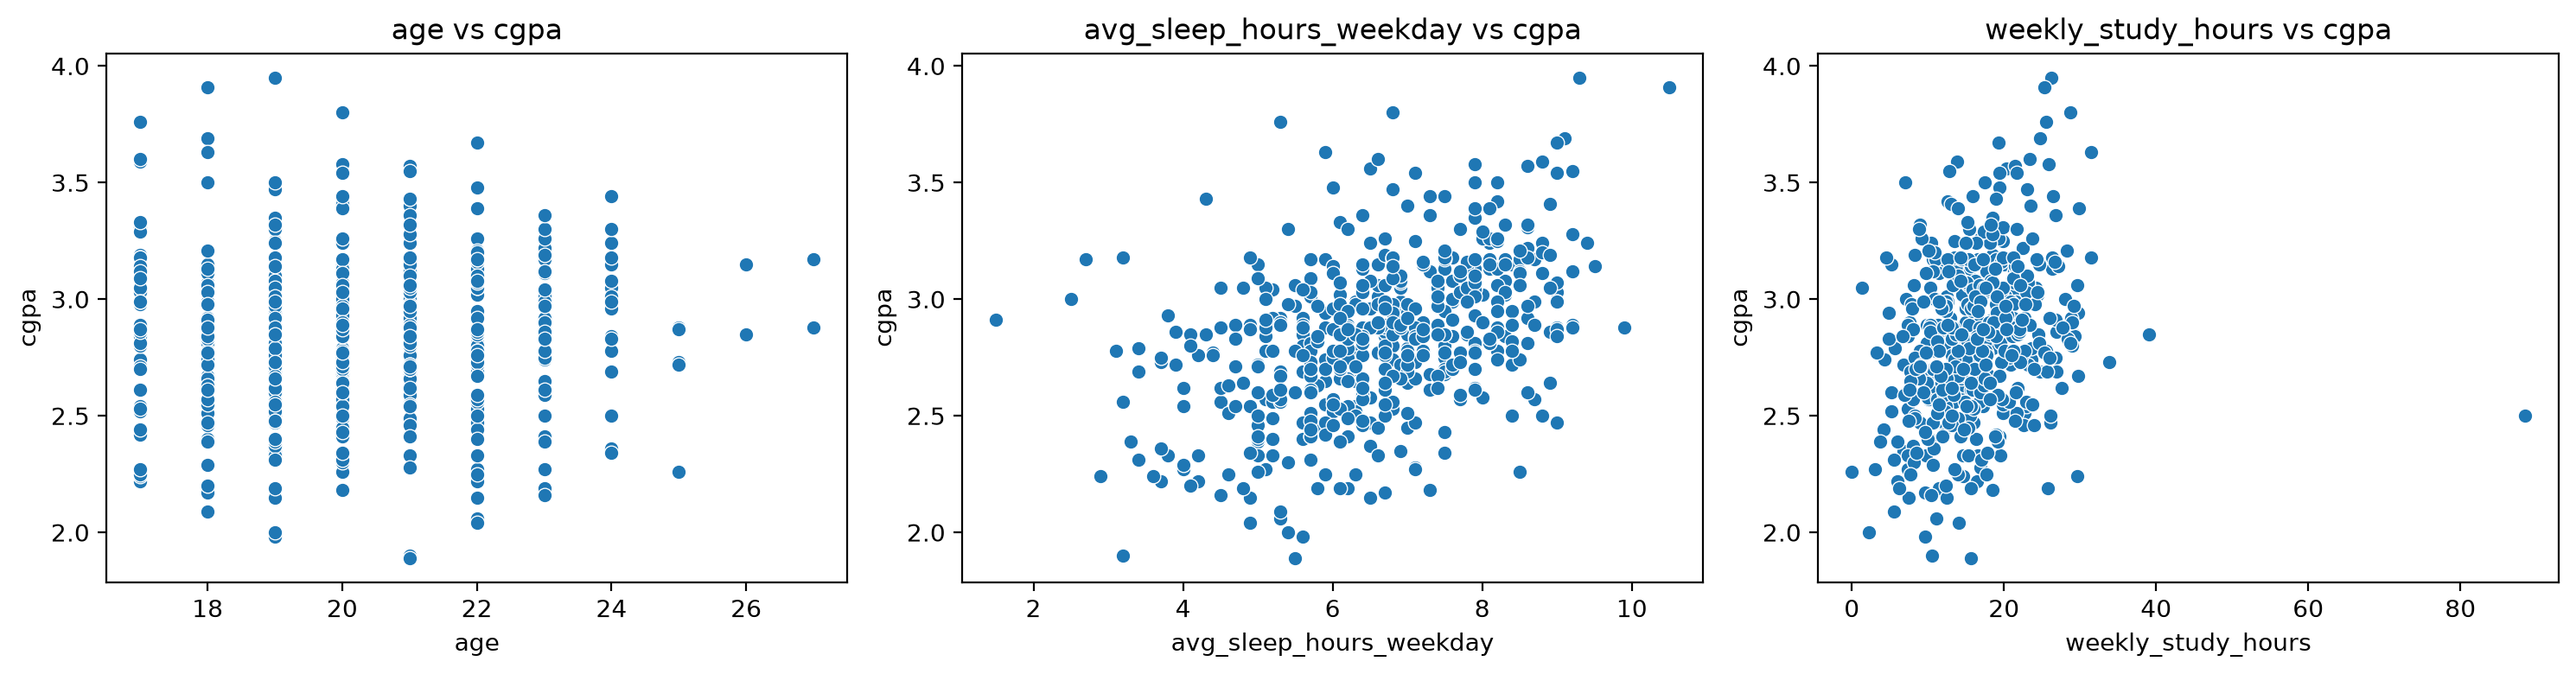

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Choisissez des colonnes existantes dans votre DataFrame
variables = ['age', 'avg_sleep_hours_weekday', 'weekly_study_hours']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, variable in zip(axes, variables):
    sns.scatterplot(
        data=df,
        x=variable,
        y="cgpa",  # Utilisation de 'cgpa' comme variable cible
        ax=ax
    )
    ax.set_title(f"{variable} vs cgpa")

plt.tight_layout()
plt.show()

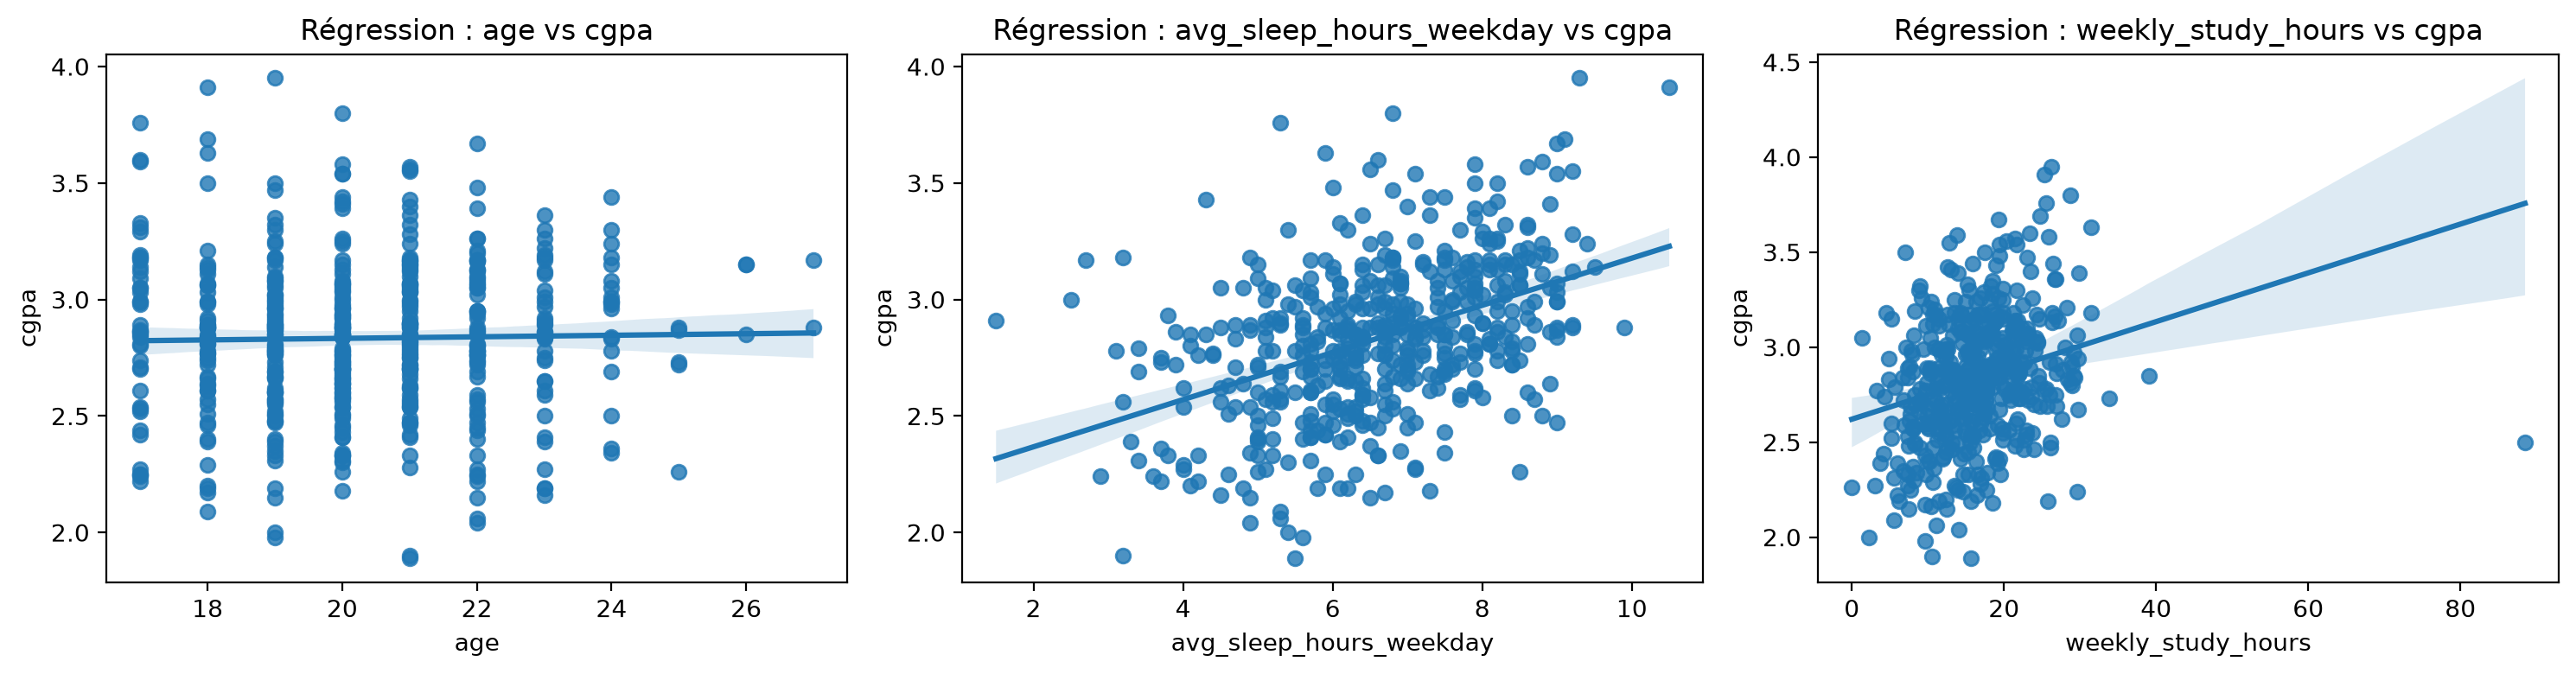

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Remplacez ces variables par celles que vous souhaitez analyser
variables = ['age', 'avg_sleep_hours_weekday', 'weekly_study_hours']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, variable in zip(axes, variables):
    sns.regplot(
        data=df,
        x=variable,
        y="cgpa",  # Remplacé "target" par "cgpa"
        ax=ax
    )
    ax.set_title(f"Régression : {variable} vs cgpa")

plt.tight_layout()
plt.show()

### Commentaire :
Que pouvons-nous observer ici ?
Tout d'abord, chacun des trois graphiques s'intéresse à la variable cible d'intérêt **CPGA** qui conrrespond à la moyenne des étudiants sondés. On exprime dans le premier graphique de gauche la regression entre l'âge et la moyenne des étudiants. Le second, quant à lui présente le lien entre la moyenne d'heure de sommeil hebdomadaire avec la moyenne des étudiants